### 1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


### 2.Load Dataset

In [2]:
df = pd.read_csv("Unemployment in India.csv")
print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


### 3.Dataset Shape Inspection

In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("\nDataset Columns:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Number of Rows: 768
Number of Columns: 7

Dataset Columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 6

### 4.Check Missing Values

In [4]:
print("Missing Values:")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Total Missing Values: 196


### 5.Data Cleaning and Type Conversion

In [5]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean text columns
df["Region"] = df["Region"].astype(str).str.strip()
df["Area"] = df["Area"].astype(str).str.strip()

# Convert Date column into datetime
df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(), dayfirst=True, errors="coerce")

# Convert numerical columns
numeric_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing essential values
df.dropna(subset=["Region", "Date"] + numeric_columns, inplace=True)
df.reset_index(drop=True, inplace=True)
print("Data Cleaning Completed!")
df.head()

Data Cleaning Completed!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


### 6.Statistical Summary

In [6]:
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


### 7.Region-wise Average Unemployment Rate

In [7]:
region_avg = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False))
print(region_avg)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


### 8.Month-wise Unemployment Trend

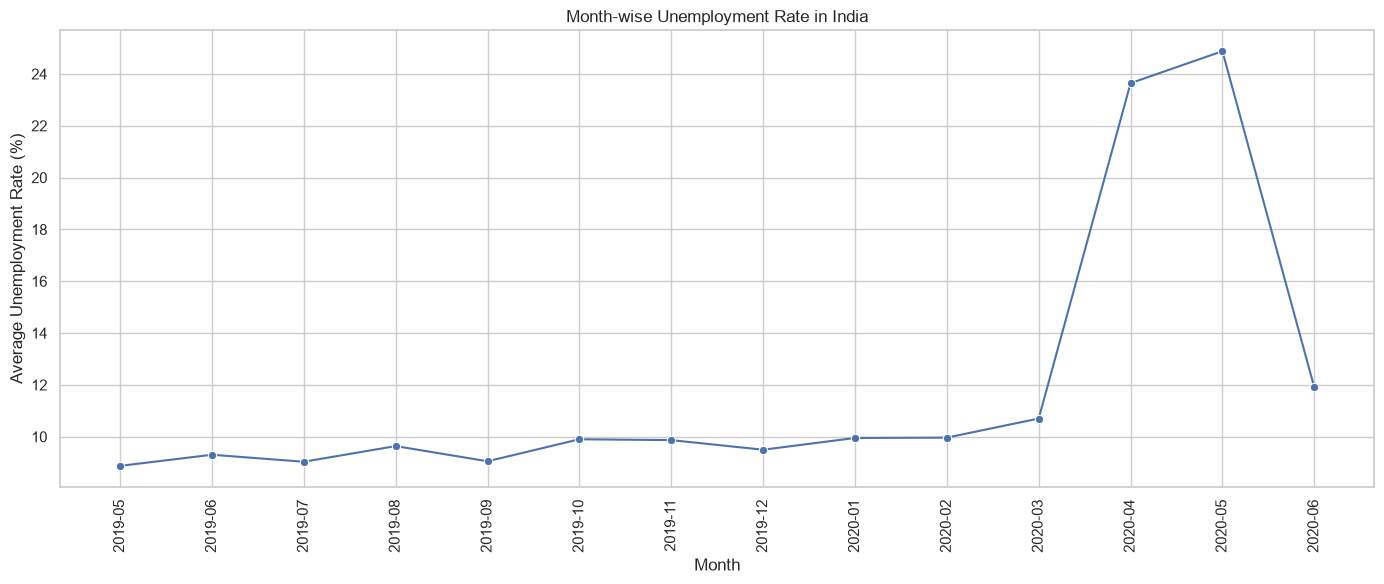

In [8]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)
monthly_unemployment = (df.groupby("Month")["Estimated Unemployment Rate (%)"].mean().reset_index())
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_unemployment, x="Month", y="Estimated Unemployment Rate (%)", marker="o")
plt.title("Month-wise Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 9.Time-Series Analysis of 3 Major States

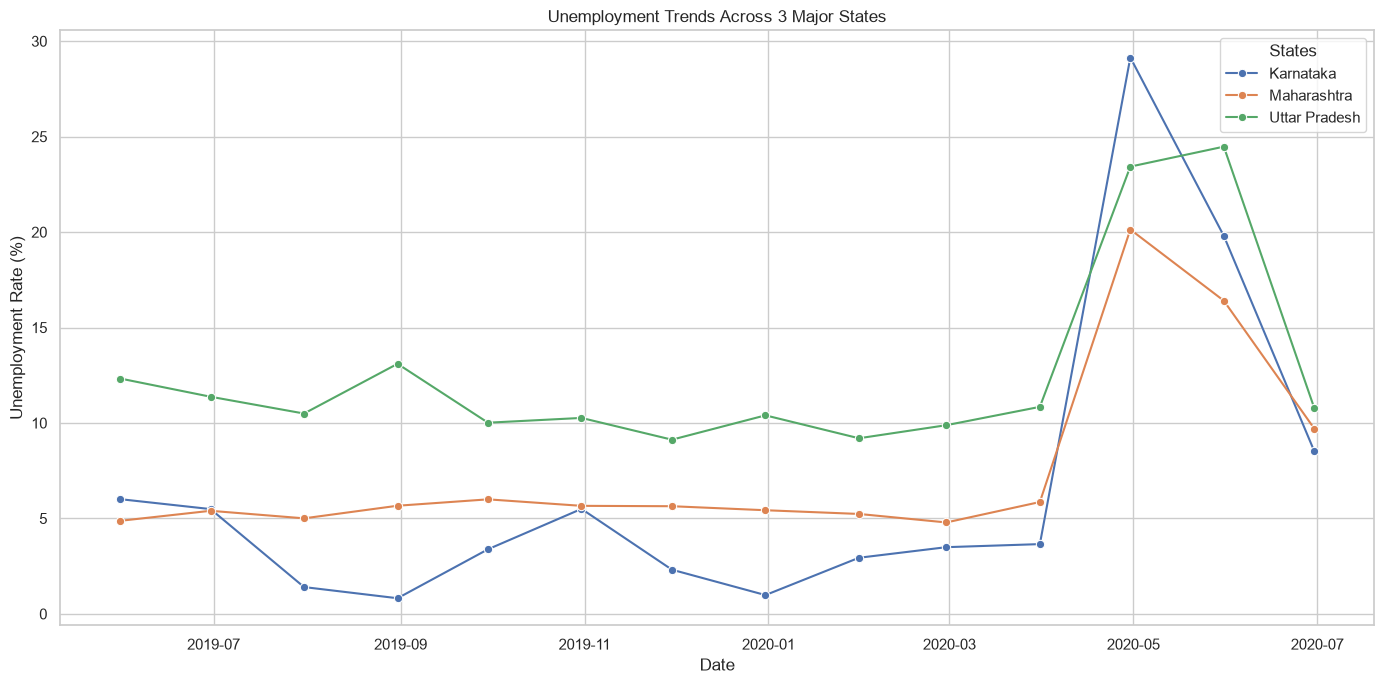

In [9]:
major_states = ["Maharashtra", "Uttar Pradesh", "Karnataka"]
state_data = df[df["Region"].isin(major_states)].copy()
state_monthly = (state_data.groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"].mean().reset_index())
plt.figure(figsize=(14, 7))
sns.lineplot(data=state_monthly, x="Date", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")
plt.title("Unemployment Trends Across 3 Major States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="States")
plt.tight_layout()
plt.show()

### 10.Top 10 States with Highest Average Unemployment

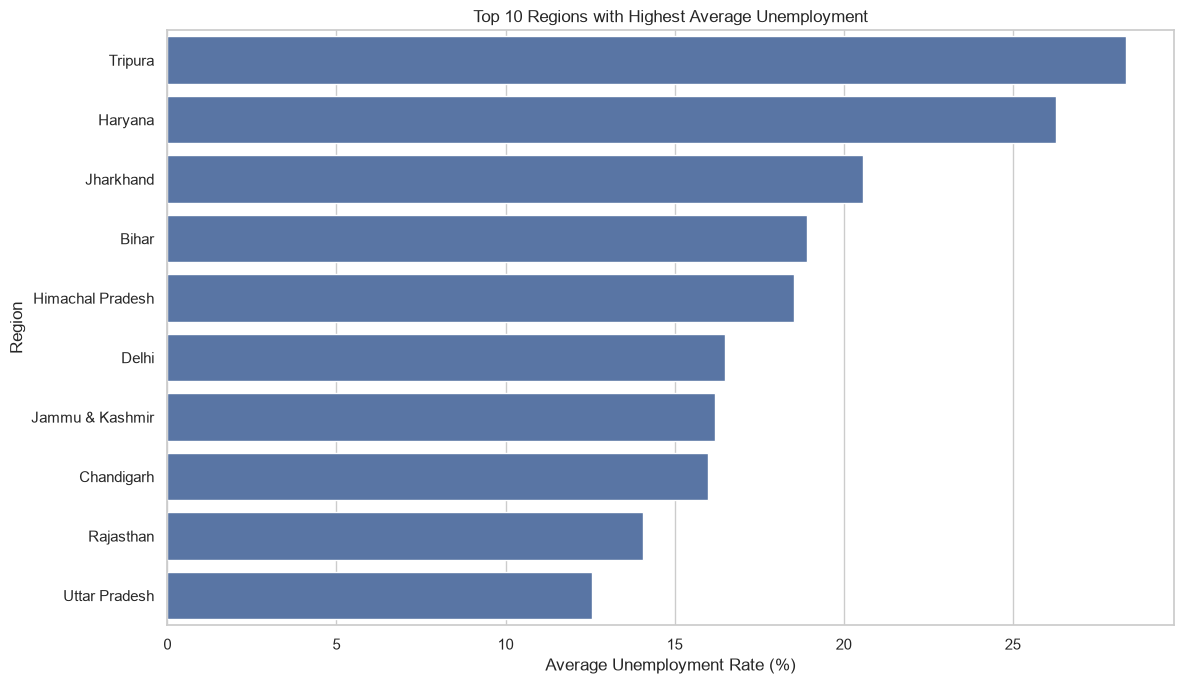

             Region  Estimated Unemployment Rate (%)
0           Tripura                        28.350357
1           Haryana                        26.283214
2         Jharkhand                        20.585000
3             Bihar                        18.918214
4  Himachal Pradesh                        18.540357
5             Delhi                        16.495357
6   Jammu & Kashmir                        16.188571
7        Chandigarh                        15.991667
8         Rajasthan                        14.058214
9     Uttar Pradesh                        12.551429


In [10]:
top_10 = region_avg.head(10).reset_index()
plt.figure(figsize=(12, 7))
sns.barplot(data=top_10, x="Estimated Unemployment Rate (%)", y="Region")
plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()
print(top_10)

### 11.Correlation Heatmap

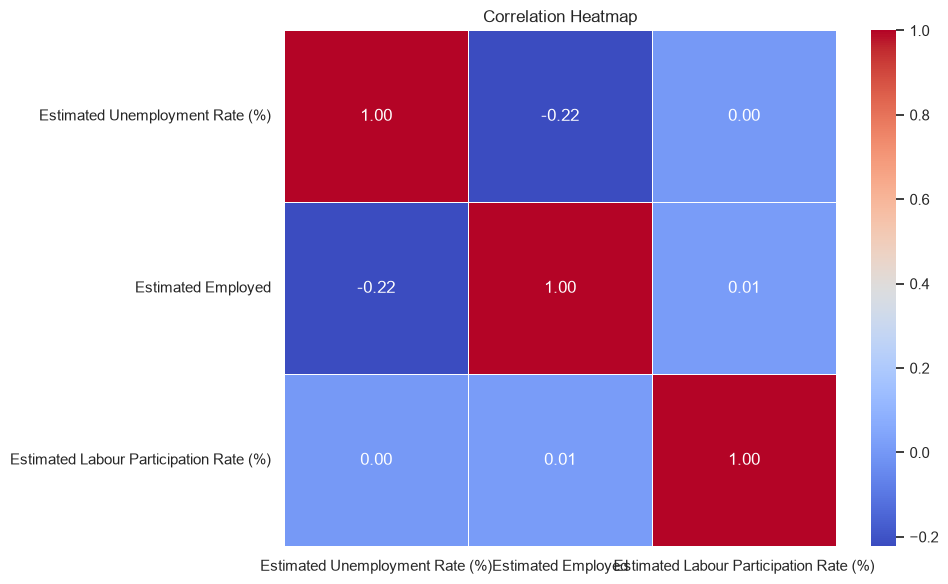

In [11]:
correlation_data = df[["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]]
correlation_matrix = correlation_data.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### 12.COVID-19 Impact Analysis

In [12]:
# Pre-COVID and Post-COVID periods
pre_covid = df[df["Date"] < "2020-03-01"]
post_covid = df[df["Date"] >= "2020-03-01"]
pre_covid_avg = pre_covid["Estimated Unemployment Rate (%)"].mean()
post_covid_avg = post_covid["Estimated Unemployment Rate (%)"].mean()
print("Pre-COVID Average Unemployment Rate:", round(pre_covid_avg, 2), "%")
print("Post-COVID Average Unemployment Rate:", round(post_covid_avg, 2), "%")
print("Difference:", round(post_covid_avg - pre_covid_avg, 2), "percentage points")

Pre-COVID Average Unemployment Rate: 9.51 %
Post-COVID Average Unemployment Rate: 17.77 %
Difference: 8.26 percentage points


### 13.COVID-19 Comparison Chart

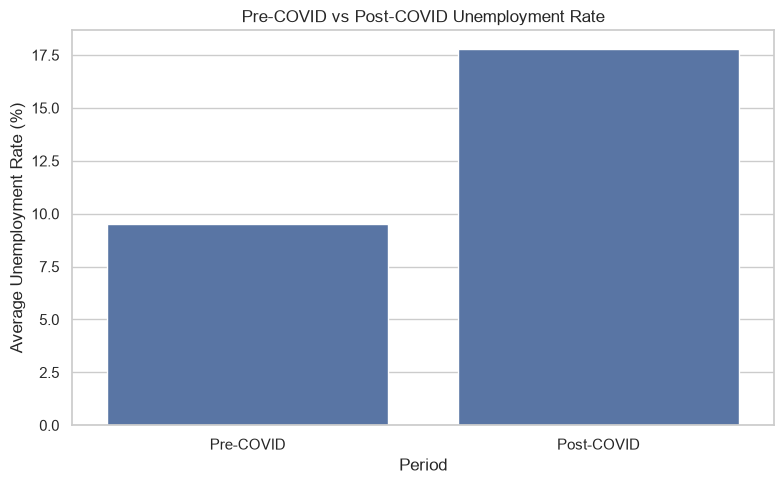

In [13]:
covid_comparison = pd.DataFrame({"Period": ["Pre-COVID", "Post-COVID"], "Average Unemployment Rate": [pre_covid_avg, post_covid_avg]})
plt.figure(figsize=(8, 5))
sns.barplot(data=covid_comparison, x="Period", y="Average Unemployment Rate")
plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

### 14.Area-wise Unemployment Analysis

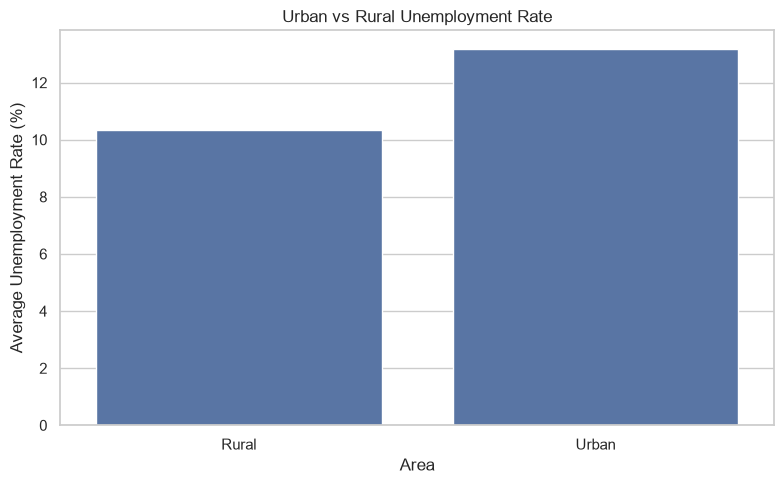

    Area  Estimated Unemployment Rate (%)
0  Rural                        10.324791
1  Urban                        13.166614


In [14]:
area_analysis = (df.groupby("Area")["Estimated Unemployment Rate (%)"].mean().reset_index())
plt.figure(figsize=(8, 5))
sns.barplot(data=area_analysis, x="Area", y="Estimated Unemployment Rate (%)")
plt.title("Urban vs Rural Unemployment Rate")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()
print(area_analysis)

### 15.Final Key Observations

In [15]:
print("========== UNEMPLOYMENT ANALYSIS ==========")

print("\n1. Highest Unemployment Region:")
print(region_avg.idxmax(), "-", round(region_avg.max(), 2), "%")

print("\n2. Lowest Unemployment Region:")
print(region_avg.idxmin(), "-", round(region_avg.min(), 2), "%")

print("\n3. Pre-COVID Average:")
print(round(pre_covid_avg, 2), "%")

print("\n4. Post-COVID Average:")
print(round(post_covid_avg, 2), "%")

print("\n5. Total Records Analyzed:", len(df))

print("\n========== ANALYSIS COMPLETED ==========")

========== UNEMPLOYMENT ANALYSIS ==========

1. Highest Unemployment Region:
Tripura - 28.35 %

2. Lowest Unemployment Region:
Meghalaya - 4.8 %

3. Pre-COVID Average:
9.51 %

4. Post-COVID Average:
17.77 %

5. Total Records Analyzed: 740

========== ANALYSIS COMPLETED ==========


### 16.Save Cleaned Dataset

In [16]:
df.to_csv("cleaned_unemployment_data.csv", index=False)
print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
